# Lesson 6.9: Choosing the Right Test

Compare incomes (in thousands) in two cities with 12 people each: check the t-test assumptions, then run both the t-test and the Mann-Whitney test and decide which to trust.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

## The question

A researcher wants to know whether household incomes differ between two cities. She samples 12 households in each (incomes in thousands). City B looks richer, but each sample contains one very large income. Which test should we trust, and is there really a difference in typical income?

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## Step 1: Enter and look at the data

H0: incomes in the two cities are distributed the same way. H1: incomes tend to be higher in one city. Always look first: each city has one very large income, which pulls its mean far above its median.

city A: mean = 50.4, median = 30.1, sd = 53.9
city B: mean = 94.1, median = 64.9, sd = 75.0


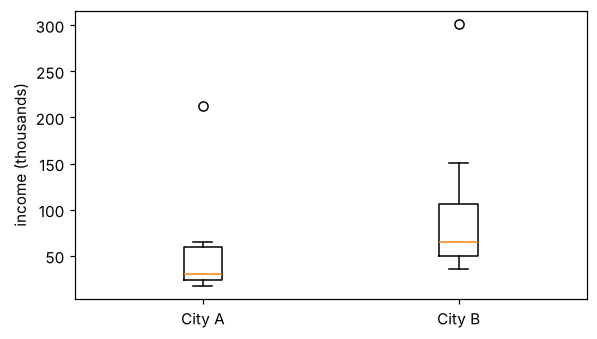

In [1]:
import numpy as np  # Load NumPy for arrays and the median, under the short name np.
from scipy import stats  # Load SciPy's statistics tools: the normality, equal-spread, t and Mann-Whitney tests.
import matplotlib.pyplot as plt  # Load matplotlib's plotting tools as plt; we use one picture here because skew is easier to see than to compute.

city_a = np.array([33.6, 26.6, 17.6, 64.6, 18.0, 23.9, 23.5, 23.2, 212.7, 39.8, 61.7, 59.1])  # Store the 12 incomes of City A, in thousands.
city_b = np.array([150.9, 42.3, 50.8, 36.2, 65.9, 95.3, 137.2, 45.7, 301.4, 50.7, 88.5, 63.9])  # Store the 12 incomes of City B in the same way.

for name, g in [('A', city_a), ('B', city_b)]:  # Loop over both cities so one block of code describes each of them.
    print(f'city {name}: mean = {g.mean():.1f}, median = {np.median(g):.1f}, sd = {g.std(ddof=1):.1f}')  # Print mean, median and SD. A mean far above the median is a sign of skew caused by a few large values.

plt.figure(figsize=(6, 3.4))  # Start a new, small figure so it fits on the page.
plt.boxplot([city_a, city_b], tick_labels=['City A', 'City B'])  # Draw side-by-side boxplots: the box is the middle half of the data and dots beyond the whiskers are unusual values.
plt.ylabel('income (thousands)')  # Label the vertical axis so the reader knows the units.
plt.show()  # Show the figure.

**What this means.** City A has mean 50.4 but median 30.1; City B has mean 94.1 and median 64.9. In each city the mean is well above the median because of one huge income, so the data are skewed. The boxplot shows that long upper tail. Means are easily pulled around by such values.

## Step 2: Check normality with Shapiro-Wilk

Shapiro-Wilk asks whether the data look like a sample from a normal curve. A p-value below 0.05 is evidence against normality. With only 12 per group, a normal-looking result would also not prove normality.

In [2]:
for name, g in [('A', city_a), ('B', city_b)]:  # Loop over the two cities to test each one the same way.
    w = stats.shapiro(g)  # Shapiro-Wilk tests whether the data look like a sample from a normal curve. The null is 'normal', so a small p-value is evidence against normality.
    verdict = 'not normal' if w.pvalue < 0.05 else 'no clear problem'  # Turn the p-value into a short verdict using alpha = 0.05.
    print(f'city {name}: W = {w.statistic:.3f}, p = {w.pvalue:.4f} ({verdict})')  # Print W (1 means perfectly normal-looking), the p-value and the verdict for each city.

city A: W = 0.601, p = 0.0001 (not normal)
city B: W = 0.735, p = 0.0019 (not normal)


**What this means.** City A: W = 0.601, p = 0.0001. City B: W = 0.735, p = 0.0019. Both are far below 0.05, so both samples are clearly not normal. This matches the boxplot. A normal-looking result with only 12 values would not have proved normality either, because these tests are weak in small samples.

## Step 3: Check equal spread with Levene

Levene's test asks whether the two groups have the same spread. We use the mean-centred version so it matches SPSS and Stata (SciPy's default centres on the median). A small p-value would mean unequal spreads.

In [3]:
lev = stats.levene(city_a, city_b, center='mean')  # Levene's test asks whether the two groups have the same spread. center='mean' matches SPSS and Stata; SciPy's default centres on the median.

print(f'Levene: statistic = {lev.statistic:.3f}, p = {lev.pvalue:.4f}')  # Print the test statistic and its p-value.
print('spreads look equal?', lev.pvalue >= 0.05)  # Print True if p is at least 0.05, meaning there is no clear evidence that the spreads differ.

Levene: statistic = 0.931, p = 0.3452
spreads look equal? True


**What this means.** Levene's statistic is 0.931 with p = 0.3452, well above 0.05, so there is no clear evidence that the spreads differ (printed True). Equal spread is one assumption the pooled t-test needs, but normality failed above, so spread alone does not rescue the t-test. Not finding a difference in spread does not prove the spreads are equal.

## Step 4: Run the t-test and Mann-Whitney

Welch's t-test compares means and is pulled around by the big incomes. The Mann-Whitney test uses ranks, so extreme values count only as 'the highest'. method='exact' gives an exact p-value when there are no ties.

In [4]:
t_res = stats.ttest_ind(city_a, city_b, equal_var=False)  # Welch's t-test compares means without assuming equal spreads. equal_var=False requests it.
u_res = stats.mannwhitneyu(city_a, city_b, method='exact', alternative='two-sided')  # Mann-Whitney U compares ranks, so a huge income only counts as 'the highest'. method='exact' gives an exact p-value when there are no ties.

print(f'Welch t-test:   t = {t_res.statistic:.3f}, p = {t_res.pvalue:.4f}')  # Print Welch's t and p.
print(f'Mann-Whitney:   U = {u_res.statistic:.1f}, p = {u_res.pvalue:.4f}')  # Print the Mann-Whitney U and p.

Welch t-test:   t = -1.638, p = 0.1170
Mann-Whitney:   U = 28.0, p = 0.0100


**What this means.** Welch's t-test gives t = -1.638 and p = 0.1170, so no significant difference in means. The Mann-Whitney test gives U = 28.0 and p = 0.0100, which is significant. Same data, opposite conclusions: the two huge incomes inflate the spread of means and hide a difference that ranks can see.

## Step 5: Decide which to trust

Both groups failed the normality check and n is small, so the rank-based test is the safer choice here. The two tests disagree at alpha = 0.05, which is a warning that outliers matter. Say which test you chose and why, before looking at p.

In [5]:
alpha = 0.05  # Fix the surprise threshold, alpha = 0.05, before comparing the decisions.
print('t-test significant?      ', t_res.pvalue <= alpha)  # Print True or False for whether the t-test reached significance.
print('Mann-Whitney significant?', u_res.pvalue <= alpha)  # Print True or False for whether the Mann-Whitney test reached significance.
print()  # Print an empty line to separate the results from the recommendation.
print('Small, skewed samples: trust the Mann-Whitney result.')  # State which test to trust and why: small, skewed samples fail the t-test's normality assumption.

t-test significant?       False
Mann-Whitney significant? True

Small, skewed samples: trust the Mann-Whitney result.


**What this means.** The t-test is not significant (False) and Mann-Whitney is (True). We trust Mann-Whitney because the normality checks failed and n is small, and we decided this from the data's shape, not from the p-values. Choosing the test that gives p < 0.05 after the fact would be cheating.

## So, what is the answer?

Typical income is higher in City B (median 64.9 against 30.1). Because both samples are clearly skewed (Shapiro p = 0.0001 and 0.0019) and small, we trust the Mann-Whitney test: U = 28, p = 0.0100. Welch's t-test (p = 0.117) is thrown off by the huge incomes. Caution: pick the test from the checks before seeing p, and with 12 households per city the checks themselves are weak.

## Now you try

A consumer group compares the repair bills (in dollars) charged by two garages for the same fault. Each garage billed 12 customers. The bills are skewed by a few expensive jobs. Check normality and equal spread, then run both Welch's t-test and the Mann-Whitney test, and say which you trust.

**Data:** g1 = [211, 123, 163, 559, 175, 144, 290, 495, 118, 220, 178, 101]
g2 = [567, 360, 381, 232, 480, 264, 335, 188, 176, 813, 269, 435]

1. Compare the medians and run Shapiro-Wilk for each garage.
2. Run Levene's test (center='mean') for equal spread.
3. Run Welch's t-test and the exact Mann-Whitney test.
4. Say which test you trust and why, and what a significant result would mean.

*Hint:* Reuse the lab's code: stats.shapiro for each garage, stats.levene(..., center='mean'), stats.ttest_ind(..., equal_var=False) and stats.mannwhitneyu(..., method='exact').

In [ ]:
# Your turn: write your code here


### Solution (try first, then peek)

In [ ]:
import numpy as np
from scipy import stats

g1 = np.array([211, 123, 163, 559, 175, 144, 290, 495, 118, 220, 178, 101])
g2 = np.array([567, 360, 381, 232, 480, 264, 335, 188, 176, 813, 269, 435])
print('medians:', np.median(g1), np.median(g2))
for name, g in [('G1', g1), ('G2', g2)]:
    print(name, 'Shapiro p =', round(stats.shapiro(g).pvalue, 4))
print('Levene p =', round(stats.levene(g1, g2, center='mean').pvalue, 4))
t = stats.ttest_ind(g1, g2, equal_var=False)
u = stats.mannwhitneyu(g1, g2, method='exact')
print(f'Welch p = {t.pvalue:.4f}, t = {t.statistic:.3f}')
print(f'Mann-Whitney U = {u.statistic}, p = {u.pvalue:.4f}')

medians: 176.5 347.5
G1 Shapiro p = 0.0049
G2 Shapiro p = 0.1447
Levene p = 0.5683
Welch p = 0.0459, t = -2.122
Mann-Whitney U = 30.0, p = 0.0145


**Answer.** Medians are 176.5 and 347.5. Shapiro p is 0.0049 for G1 (not normal) and 0.1447 for G2; Levene p = 0.5683 (no clear difference in spread). Welch gives t = -2.122, p = 0.0459 and Mann-Whitney U = 30.0, p = 0.0145. Both are below 0.05, but G1 is skewed and n is small, so trust Mann-Whitney: garage 2 tends to bill more. That cannot say why.

## The same question in R, SPSS and Stata

**R**

```r
a <- c(33.6, 26.6, 17.6, 64.6, 18, 23.9, 23.5, 23.2, 212.7, 39.8, 61.7, 59.1)  # Store City A's 12 incomes in a vector.
b <- c(150.9, 42.3, 50.8, 36.2, 65.9, 95.3, 137.2, 45.7, 301.4, 50.7, 88.5, 63.9)  # Store City B's 12 incomes in a vector.
shapiro.test(a); shapiro.test(b)  # Shapiro-Wilk normality test for each city; semicolons put two commands on one line.

income <- c(a, b); city <- factor(rep(c("A", "B"), each = 12))  # Stack both cities in one vector with a matching city label (factor) for each value.
dev <- abs(income - ave(income, city))   # Levene = ANOVA on distances from the group mean  # Distance of each value from its own city's mean; Levene's test is an ANOVA on these distances.
anova(lm(dev ~ city))  # anova(lm(...)) tests whether the average distance differs by city; its F is Levene's statistic.

t.test(a, b)          # Welch  # Welch's t-test (R's default for two samples).
wilcox.test(a, b)     # Mann-Whitney (W equals U)  # wilcox.test on two vectors is the Mann-Whitney test; R calls its statistic W (the same number as U).
```

How to read it: Both Shapiro p-values (0.0001092 and 0.001881) are below 0.05: not normal. Levene's F = 0.9306 has p = 0.3452: no clear difference in spread. Welch gives p-value = 0.117 (not significant) while wilcox.test gives W = 28, p-value = 0.01004 (significant). Trust the rank test.

**SPSS** (Analyze > Descriptive Statistics > Explore (Plots > Normality plots with tests); Analyze > Compare Means > Independent-Samples T Test; Analyze > Nonparametric Tests > Legacy Dialogs > 2 Independent Samples)

```
DATA LIST FREE / city income.
BEGIN DATA
1 33.6 1 26.6 1 17.6 1 64.6 1 18 1 23.9
1 23.5 1 23.2 1 212.7 1 39.8 1 61.7 1 59.1
2 150.9 2 42.3 2 50.8 2 36.2 2 65.9 2 95.3
2 137.2 2 45.7 2 301.4 2 50.7 2 88.5 2 63.9
END DATA.
EXAMINE VARIABLES=income BY city
  /PLOT=NPPLOT.
T-TEST GROUPS=city(1 2)
  /VARIABLES=income.
NPAR TESTS
  /M-W=income BY city(1 2).
```

How to read it: In Tests of Normality, Shapiro-Wilk Sig. is about 0.000 and 0.002 (not normal). In the t-test table Levene's Sig. is 0.345; read the 'not assumed' row for Welch (Sig. about 0.117). In Mann-Whitney, use Exact Sig. (2-tailed), about 0.010.

**Stata**

```
clear
set obs 24
generate city = 1 + (_n > 12)
generate income = real(word("33.6 26.6 17.6 64.6 18 23.9 23.5 23.2 212.7 39.8 61.7 59.1 150.9 42.3 50.8 36.2 65.9 95.3 137.2 45.7 301.4 50.7 88.5 63.9", _n))
swilk income if city == 1
swilk income if city == 2
robvar income, by(city)
ttest income, by(city) unequal
ranksum income, by(city)
```

How to read it: swilk shows Prob>z of about 0.0001 and 0.002 (not normal). In robvar read W0 = 0.9306 with Pr > F = 0.345. ttest, unequal gives a two-sided p of about 0.117. ranksum gives a z-based p of about 0.010 (and an exact p of 0.0100 for small samples). Trust the rank test.